## Analysis of sepsis stays (2018-2024)

in response to Subquestion 1: How did sepsis MCC discharge shares change from 2018 to 2024, and did trends differ between hospitals in regions classified as AI-adoption hotspots and coldspots in 2023-2024?

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# input file from get_data.ipynb
DATA_FILE = Path("hospital_data_expanded.csv")

CCN_COL = "Rndrng_Prvdr_CCN"     # variable names
YEAR_COL = "data_year"
DRG_COL = "DRG_Cd"
COUNT_COL = "Tot_Dschrgs"
HSA_COL = "hsa_id"
CLASS_COL = "hsa_classification"

HOT_LABEL = 1        # geographic labels
COLD_LABEL = -1

YEARS = list(range(2018, 2025))
REFERENCE_YEAR = 2018

N_BOOTSTRAPS = 1000     # bootstrap settings
RANDOM_SEED = 42

OUTPUT_DIR = Path("sepsis_results")     # output folder
OUTPUT_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_colwidth", None)

In [3]:
# loading & filtering sepsis data

raw = pd.read_csv(DATA_FILE, dtype="string")
raw.columns = raw.columns.str.strip()

column_mapping = {
    CCN_COL: "hospital",
    YEAR_COL: "year",
    DRG_COL: "drg",
    COUNT_COL: "discharges",
    HSA_COL: "hsa",
    CLASS_COL: "classification"
}

data = raw[list(column_mapping)].rename(columns=column_mapping).copy()

for col in ["year", "drg", "classification"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")
data["discharges"] = pd.to_numeric(
    data["discharges"].str.replace(",", "", regex=False),
    errors="coerce"
)

# keeping sepsis data (DRGs 871 & 872)

data = data.loc[
    data["year"].isin(YEARS)
    & data["drg"].isin([871, 872])
].copy()

data["year"] = data["year"].astype(int)
data["drg"] = data["drg"].astype(int)

print("Sepsis rows loaded:", len(data))
display(data.head())

Sepsis rows loaded: 8475


,hospital,year,drg,discharges,hsa,classification
123,010001,2018,871,505,1026,-1
124,010001,2018,872,110,1026,-1
150,010007,2018,871,16,1065,-1
151,010007,2018,872,16,1065,-1
232,010040,2018,871,346,1039,1


In [4]:
# standardizing HSAs

data["hsa_original"] = data["hsa"]

# find each hospital's latest year with a known HSA
known_hsa = data.loc[data["hsa"].notna()].copy()
latest_year = (
    known_hsa.groupby("hospital")["year"]
    .transform("max")
)
latest_hsa = (
    known_hsa.loc[
        known_hsa["year"].eq(latest_year),
        ["hospital", "hsa"]
    ]
    .drop_duplicates()
)
# check if the latest year itself has conflicting assignments
if latest_hsa["hospital"].duplicated().any():
    raise ValueError("Multiple HSAs in a hospital's latest year")
hsa_lookup = latest_hsa.set_index("hospital")["hsa"]
# assign a fixed HSA across each hospital's records
data["hsa"] = data["hospital"].map(hsa_lookup)

# validating records

# check for duplicate records
keys = ["hospital", "year", "drg"]
duplicates = data.loc[data.duplicated(keys, keep=False)]
if not duplicates.empty:
    display(duplicates.sort_values(keys).head(30))
    raise ValueError("Duplicate hospital-year-DRG records found")

# check for conflicting classifications:
# a hospital has to have one HSA and one classification
    # HSA conflict for 3 hospitals resolved by latest_year/hsa code above
hospital_checks = (
    data.groupby("hospital")
    .agg(
        n_hsas=("hsa", "nunique"),
        n_classes=("classification", "nunique")
    )
)
inconsistent = hospital_checks.loc[
    (hospital_checks["n_hsas"] > 1)
    | (hospital_checks["n_classes"] > 1)
]
if not inconsistent.empty:
    display(inconsistent)
    raise ValueError("Some hospitals change HSA or classification")
# check that each HSA has one classification
hsa_checks = data.groupby("hsa")["classification"].nunique()
if (hsa_checks > 1).any():
    raise ValueError("At least one HSA has conflicting classifications")

print("Classification counts before filtering:")
display(data["classification"].value_counts(dropna=False))

eligible = data.loc[
    data["classification"].isin([HOT_LABEL, COLD_LABEL])
    & data["hospital"].notna()
    & data["hsa"].notna()
].copy()

# report missing discharge values
print(
    "Rows with missing discharge counts:",
    eligible["discharges"].isna().sum()
)

Classification counts before filtering:


classification
1     5590
-1    2885
Name: count, dtype: Int64

Rows with missing discharge counts: 0


calculating hospital-year MCC shares & defining samples
- missing counts are left missing
- primary sample requires at least two complete years
- balanced sample requires all seven

In [5]:
# arranging DRG counts into one row per hospital-year

counts = eligible.pivot(
    index=["hospital", "year"],
    columns="drg",
    values="discharges"
).reindex(columns=[871, 872])

metadata = (
    eligible.groupby(["hospital", "year"], as_index=False)
    .agg(
        hsa=("hsa", "first"),
        classification=("classification", "first")
    )
)
panel = (
    counts.rename(columns={871: "n_871", 872: "n_872"})
    .reset_index()
    .merge(
        metadata,
        on=["hospital", "year"],
        how="left",
        validate="one_to_one"
    )
)
panel["group"] = np.where(
    panel["classification"] == HOT_LABEL,
    "Hotspot",
    "Coldspot"
)
panel["complete"] = panel[["n_871", "n_872"]].notna().all(axis=1)

coverage = (
    panel.groupby(["year", "group"])
    .agg(
        observed_hospitals=("hospital", "nunique"),
        complete_hospitals=("complete", "sum")
    )
    .reset_index()
)

# calculating MCC shares
# note: observed_hospitals counts hospitals with at least one reported sepsis code
coverage["excluded_hospitals"] = (
    coverage["observed_hospitals"] - coverage["complete_hospitals"]
)
coverage["retention_pct"] = (
    100 * coverage["complete_hospitals"]
    / coverage["observed_hospitals"]
)

display(coverage)

complete_panel = panel.loc[panel["complete"]].copy()
complete_panel["sepsis_discharges"] = (
    complete_panel["n_871"] + complete_panel["n_872"]
)
complete_panel["mcc_share"] = (
    complete_panel["n_871"]
    / complete_panel["sepsis_discharges"]
)

# % units
complete_panel["mcc_pct"] = 100 * complete_panel["mcc_share"]

# defining our primary sample: at least two calculable years per hospital

years_per_hospital = (complete_panel.groupby("hospital")["year"].nunique())
primary_ids = years_per_hospital[years_per_hospital >= 2].index
primary = complete_panel.loc[complete_panel["hospital"].isin(primary_ids)].copy()

# balanced sample (for sensitivity): complete in all seven years

balanced_ids = years_per_hospital[years_per_hospital == len(YEARS)].index
balanced = complete_panel.loc[complete_panel["hospital"].isin(balanced_ids)].copy()

print("Primary hospital-year observations:", len(primary))
print("Primary distinct hospitals:", primary["hospital"].nunique())
print("Balanced distinct hospitals:", balanced["hospital"].nunique())

,year,group,observed_hospitals,complete_hospitals,excluded_hospitals,retention_pct
0,2018,Coldspot,237,212,25,89.451477
1,2018,Hotspot,425,403,22,94.823529
2,2019,Coldspot,230,208,22,90.434783
3,2019,Hotspot,424,398,26,93.867925
4,2020,Coldspot,223,191,32,85.650224
5,2020,Hotspot,422,380,42,90.047393
6,2021,Coldspot,221,184,37,83.257919
7,2021,Hotspot,425,370,55,87.058824
8,2022,Coldspot,225,171,54,76.000000
9,2022,Hotspot,425,354,71,83.294118


Primary hospital-year observations: 3917
Primary distinct hospitals: 625
Balanced distinct hospitals: 468


summarizing hospital and HSA counts, discharge volumes, & MCC-share distributions by year-group
- plot reflects mean hospital MCC shares

,year,group,hospitals,hsas,reported_sepsis_discharges,mean_mcc_pct,median_mcc_pct,sd_mcc_pct
0,2018,Coldspot,207,149,56663,76.13,78.65,9.55
1,2018,Hotspot,394,228,126763,78.13,78.6,5.67
2,2019,Coldspot,202,145,55060,77.17,78.85,8.18
3,2019,Hotspot,394,226,123543,78.41,78.94,5.68
4,2020,Coldspot,191,136,49068,79.85,81.94,9.18
5,2020,Hotspot,378,218,116232,81.47,82.05,5.7
6,2021,Coldspot,184,134,43310,80.19,82.27,8.35
7,2021,Hotspot,370,214,105656,81.5,81.99,5.75
8,2022,Coldspot,171,126,41729,81.43,83.4,8.53
9,2022,Hotspot,353,204,105163,82.89,83.75,5.0


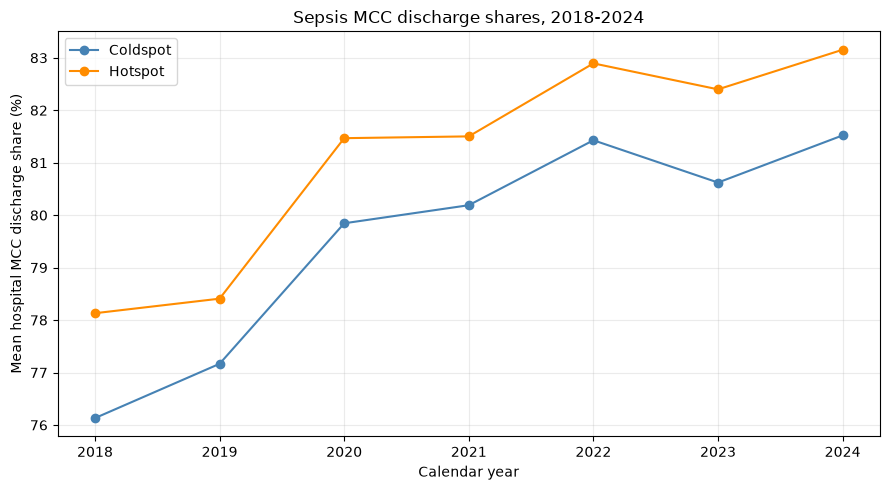

In [6]:
# annual summary by group

def annual_summary(frame):
    return (
        frame.groupby(["year", "group"])
        .agg(
            hospitals=("hospital", "nunique"),
            hsas=("hsa", "nunique"),
            reported_sepsis_discharges=("sepsis_discharges", "sum"),
            mean_mcc_pct=("mcc_pct", "mean"),
            median_mcc_pct=("mcc_pct", "median"),
            sd_mcc_pct=("mcc_pct", "std")
        )
        .reset_index()
    )

annual = annual_summary(primary)
display(annual.round(2))

fig, ax = plt.subplots(figsize=(9, 5))

colors = {"Hotspot": "darkorange", "Coldspot": "steelblue"}
for group, subset in annual.groupby("group"):
    ax.plot(
        subset["year"],
        subset["mean_mcc_pct"],
        marker="o",
        label=group,
        color=colors[group]
    )

ax.set(
    xlabel="Calendar year",
    ylabel="Mean hospital MCC discharge share (%)",
    title="Sepsis MCC discharge shares, 2018-2024"
)
ax.set_xticks(YEARS)
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "annual_mcc_shares.png", dpi=300)

plt.show()

In [7]:
# results

print(
    f"Primary analysis included {len(primary):,} hospital-year "
    f"observations from {primary['hospital'].nunique():,} hospitals "
    f"in {primary['hsa'].nunique():,} HSAs."
)

for group in ["Coldspot", "Hotspot"]:
    subset = annual.loc[annual["group"] == group].set_index("year")

    first = subset.loc[2018, "mean_mcc_pct"]
    last = subset.loc[2024, "mean_mcc_pct"]

    print(
        f"{group}: descriptive mean MCC share was "
        f"{first:.2f}% in 2018 and {last:.2f}% in 2024."
    )

Primary analysis included 3,917 hospital-year observations from 625 hospitals in 386 HSAs.
Coldspot: descriptive mean MCC share was 76.13% in 2018 and 81.52% in 2024.
Hotspot: descriptive mean MCC share was 78.13% in 2018 and 83.15% in 2024.


> This primary analysis included 3,917 hospital observations from 625 hospitals across 386 HSAs. Mean hospital-level sepsis MCC shares increased from 2018 to 2024 by 5.39 percentage points in coldspots (from 76.13% to 81.52%) and by 5.02 in hotspots (from 78.13% to 83.15%).

adjusted MCC trend differences using hospital fixed-effects regression
- removing each hospital's average to account for stable hospital differences
- determining annual patterns & hotspot x year interactions

In [8]:
MODEL_YEARS = [
    year for year in YEARS
    if year != REFERENCE_YEAR
]

def prepare_fixed_effects(frame):
    frame = frame.reset_index(drop=True).copy()
    # require observations from both classes in each year
    year_groups = (
        frame.groupby(["year", "group"])
        .size()
        .unstack(fill_value=0)
        .reindex(
            index=YEARS,
            columns=["Coldspot", "Hotspot"],
            fill_value=0
        )
    )
    hotspot = (
        frame["classification"].eq(HOT_LABEL)
        .astype(float)
        .to_numpy()
    )

    X = pd.DataFrame(index=frame.index)

    for year in MODEL_YEARS:
        year_indicator = frame["year"].eq(year).astype(float)

        X[f"year_{year}"] = year_indicator
        X[f"hotspot_x_{year}"] = year_indicator * hotspot

    y = frame["mcc_pct"].astype(float)

    # within-hospital demeaning
    X_within = X - X.groupby(frame["hospital"]).transform("mean")
    y_within = y - y.groupby(frame["hospital"]).transform("mean")

    return (
        frame,
        X_within.to_numpy(dtype=float),
        y_within.to_numpy(dtype=float),
        X.columns.tolist()
    )

def fit_coefficients(X, y):
    if np.linalg.matrix_rank(X) < X.shape[1]:
        raise ValueError(
            "Model is not identifiable in this sample."
        )
    beta, _, _, _ = np.linalg.lstsq(X, y, rcond=None)
    return beta

model_frame, X, y, feature_names = prepare_fixed_effects(primary)
beta = fit_coefficients(X, y)

coefficient_table = pd.DataFrame({
    "term": feature_names,
    "estimate_pp": beta
})

display(coefficient_table)

,term,estimate_pp
0,year_2019,0.913957
1,hotspot_x_2019,-0.648959
2,year_2020,3.099189
3,hotspot_x_2020,0.077238
4,year_2021,3.015661
5,hotspot_x_2021,0.343328
6,year_2022,4.472747
7,hotspot_x_2022,0.192486
8,year_2023,3.594306
9,hotspot_x_2023,0.744346


HSA-level bootstrap
- repeatedly sampling HSAs within each geographic group (retaining their hospitals and years)
- refitting the model across samples to estimate uncertainty while preserving dependence w/in HSAs

In [9]:
def bootstrap_fixed_effects(frame, n_bootstraps, seed):
    model_frame, X, y, names = prepare_fixed_effects(frame)
    point_estimate = fit_coefficients(X, y)

    hsa_groups = (
        model_frame[["hsa", "group"]]
        .drop_duplicates()
    )
    group_hsas = {
        group: subset["hsa"].to_numpy()
        for group, subset in hsa_groups.groupby("group")
    }
    cluster_counts = {
        group: len(hsas)
        for group, hsas in group_hsas.items()
    }

    print("HSAs available for bootstrap:", cluster_counts)

    if any(count < 2 for count in cluster_counts.values()):
        raise ValueError(
            "At least two HSAs per group are required; "
            "few HSAs still make inference unreliable."
        )

    cluster_indices = (
        model_frame.groupby("hsa", sort=False).indices
    )

    rng = np.random.default_rng(seed)
    estimates = []
    failed = 0

    for b in range(n_bootstraps):
        sampled_hsas = []

        for group in ["Coldspot", "Hotspot"]:
            hsas = group_hsas[group]

            sampled_hsas.extend(
                rng.choice(hsas, size=len(hsas), replace=True)
            )
        row_indices = np.concatenate([
            cluster_indices[hsa] for hsa in sampled_hsas
        ])

        try:
            estimates.append(
                fit_coefficients(X[row_indices], y[row_indices])
            )
        except ValueError:
            failed += 1

        if (b + 1) % 200 == 0:
            print(f"Completed {b + 1}/{n_bootstraps}")

    bootstrap_estimates = np.vstack(estimates)

    if failed / n_bootstraps > 0.05:
        raise ValueError(f"{failed} bootstrap models were not identifiable")

    lower, upper = np.quantile(
        bootstrap_estimates,
        [0.025, 0.975],
        axis=0
    )

    results = pd.DataFrame({
        "term": names,
        "estimate_pp": point_estimate,
        "ci_lower_pp": lower,
        "ci_upper_pp": upper
    })

    print("Successful bootstrap samples:", len(estimates))
    print("Non-identifiable samples:", failed)

    return results

results = bootstrap_fixed_effects(primary, n_bootstraps=N_BOOTSTRAPS, seed=RANDOM_SEED)

interaction_results = results.loc[
    results["term"].str.startswith("hotspot_x_")
].copy()
interaction_results["year"] = (
    interaction_results["term"]
    .str.extract(r"(\d{4})")[0]
    .astype(int)
)

display(
    interaction_results[
        ["year", "estimate_pp", "ci_lower_pp", "ci_upper_pp"]
    ].round(3)
)

HSAs available for bootstrap: {'Coldspot': 157, 'Hotspot': 229}
Completed 200/1000
Completed 400/1000
Completed 600/1000
Completed 800/1000
Completed 1000/1000
Successful bootstrap samples: 1000
Non-identifiable samples: 0


,year,estimate_pp,ci_lower_pp,ci_upper_pp
1,2019,-0.649,-1.652,0.224
3,2020,0.077,-1.197,1.205
5,2021,0.343,-0.830,1.510
7,2022,0.192,-0.984,1.313
9,2023,0.744,-0.299,1.829
11,2024,0.418,-0.853,1.636


plotting adjusted differences
- annual hotspot-coldspot differences in change relative to 2018, 95% bootstrap confidence intervals
- zero = no difference in the groups' changes

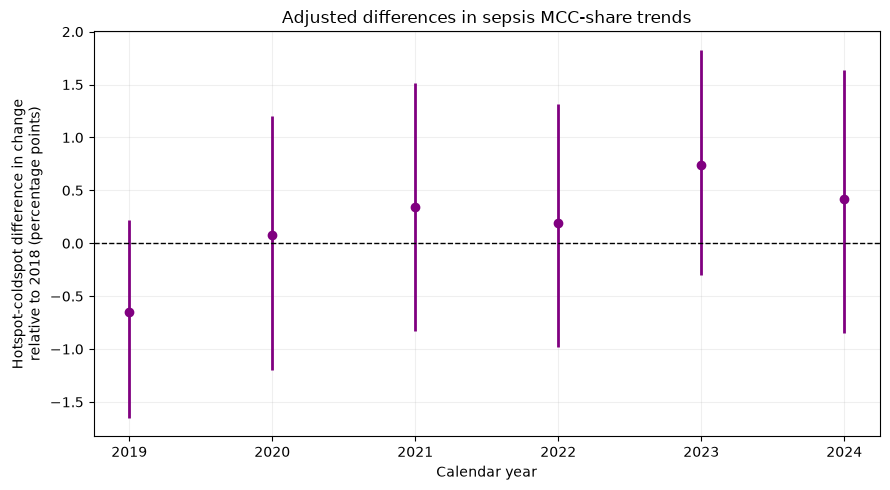

In [10]:
plot_data = interaction_results.sort_values("year")

fig, ax = plt.subplots(figsize=(9, 5))

# drawing intervals directly
ax.vlines(
    plot_data["year"],
    plot_data["ci_lower_pp"],
    plot_data["ci_upper_pp"],
    color="purple",
    linewidth=2
)

ax.scatter(
    plot_data["year"],
    plot_data["estimate_pp"],
    color="purple",
    zorder=3
)

ax.axhline(0, color="black", linestyle="--", linewidth=1)

ax.set(
    xlabel="Calendar year",
    ylabel="Hotspot-coldspot difference in change\n"
           "relative to 2018 (percentage points)",
    title="Adjusted differences in sepsis MCC-share trends"
)

ax.set_xticks(MODEL_YEARS)
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "adjusted_trend_differences.png", dpi=300)

plt.show()

In [11]:
# results
# 
estimate_2024 = interaction_results.loc[
    interaction_results["year"] == 2024
].iloc[0]

print(
    "\nAdjusted hotspot-coldspot difference in change "
    "from 2018 to 2024 was "
    f"{estimate_2024['estimate_pp']:.2f} percentage points "
    f"(95% bootstrap CI "
    f"{estimate_2024['ci_lower_pp']:.2f} to "
    f"{estimate_2024['ci_upper_pp']:.2f})."
)


Adjusted hotspot-coldspot difference in change from 2018 to 2024 was 0.42 percentage points (95% bootstrap CI -0.85 to 1.64).


> After accounting for stable hospital differences and for calendar year, the estimated hotspot-coldspot difference in change from 2018 to 2024 was 0.42 percentage points (95% bootstrap CI: -0.85 to 1.64). All individual-year interaction intervals included zero, indicating a lack of clear evidence that changes in sepsis MCC shares differed between the geographic groups.

balanced-panel sesnitivity analysis
- repeating model only for hospitals with both DRGs reported in every year (checks impact of changing  hospital composition)

In [12]:
balanced_counts = (
    balanced.groupby("group")
    .agg(
        hospitals=("hospital", "nunique"),
        hsas=("hsa", "nunique")
    )
)
display(balanced_counts)

balanced_results = None

# check there's enough geographic coverage
# & both groups appear
if (
    {"Hotspot", "Coldspot"}.issubset(balanced_counts.index)
    and balanced_counts["hsas"].min() >= 2
):
    balanced_results = bootstrap_fixed_effects(
        balanced,
        n_bootstraps=N_BOOTSTRAPS,
        seed=RANDOM_SEED + 1    # new seed
    )

    # compare w/ primary analysis
    # using annual interaction estimates
    comparison = (
        results.loc[
            results["term"].str.startswith("hotspot_x_")
        ]
        .merge(     # matched up nice&neat
            balanced_results.loc[
                balanced_results["term"].str.startswith("hotspot_x_")
            ],
            on="term",
            suffixes=("_primary", "_balanced")
        )
    )

    display(comparison.round(3))

else:
    print(
        "Insufficient geographic coverage"
    )

,hospitals,hsas
group,,
Coldspot,144,105
Hotspot,324,196


HSAs available for bootstrap: {'Coldspot': 105, 'Hotspot': 196}
Completed 200/1000
Completed 400/1000
Completed 600/1000
Completed 800/1000
Completed 1000/1000
Successful bootstrap samples: 1000
Non-identifiable samples: 0


,term,estimate_pp_primary,ci_lower_pp_primary,ci_upper_pp_primary,estimate_pp_balanced,ci_lower_pp_balanced,ci_upper_pp_balanced
0,hotspot_x_2019,-0.649,-1.652,0.224,-0.367,-1.331,0.559
1,hotspot_x_2020,0.077,-1.197,1.205,-0.477,-1.725,0.671
2,hotspot_x_2021,0.343,-0.830,1.510,-0.160,-1.434,1.126
3,hotspot_x_2022,0.192,-0.984,1.313,-0.238,-1.504,0.871
4,hotspot_x_2023,0.744,-0.299,1.829,0.342,-0.905,1.475
5,hotspot_x_2024,0.418,-0.853,1.636,0.056,-1.366,1.381


> Restricting analysis to the 468 hospitals observed in all seven years produced a 2024 difference in change of 0.06 percentage points (95% CI: -1.37 to 1.38). This is consistent with the primary results and suggest that the absence of a clear differential change was not dependent on variation of hospital participation across years. To note is that the sample used for this analysis may disproportionately represent hospitals with higher sepsis discharge volumes.

coverage analysis (checking coverage by year and group)
- calculating the % of hospital-years with both DRGs reported among those w/ at least one reported sepsis DRG
- plot shows how completeness varies across years & by geographic group

,year,group,observed_hospitals,complete_hospitals,hsas,excluded_hospitals,complete_pct
0,2018,Coldspot,237,212,172,25,89.45
1,2018,Hotspot,425,403,242,22,94.82
2,2019,Coldspot,230,208,169,22,90.43
3,2019,Hotspot,424,398,241,26,93.87
4,2020,Coldspot,223,191,163,32,85.65
5,2020,Hotspot,422,380,239,42,90.05
6,2021,Coldspot,221,184,165,37,83.26
7,2021,Hotspot,425,370,239,55,87.06
8,2022,Coldspot,225,171,164,54,76.00
9,2022,Hotspot,425,354,238,71,83.29


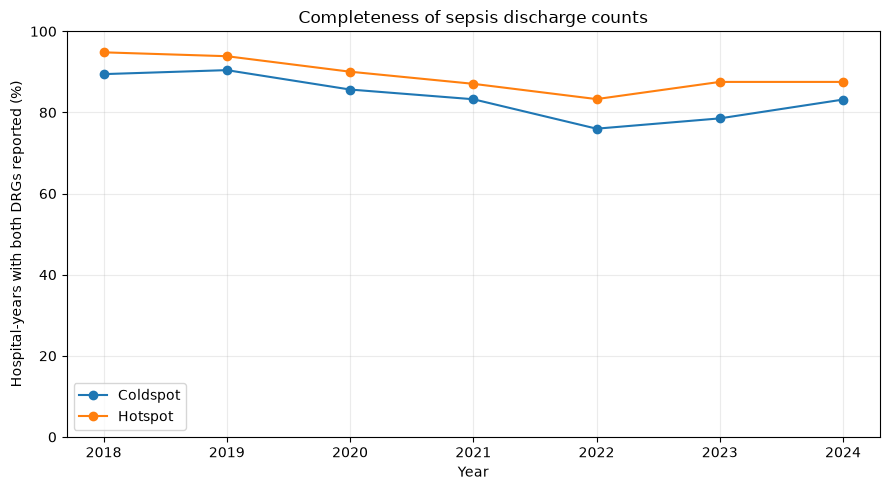

In [13]:
coverage_check = (
    panel.groupby(["year", "group"])
    .agg(
        observed_hospitals=("hospital", "nunique"),
        complete_hospitals=("complete", "sum"),
        hsas=("hsa", "nunique")
    )
    .reset_index()
)

coverage_check["excluded_hospitals"] = (
    coverage_check["observed_hospitals"]
    - coverage_check["complete_hospitals"]
)

coverage_check["complete_pct"] = (
    100 * coverage_check["complete_hospitals"]
    / coverage_check["observed_hospitals"]
)

display(coverage_check.round(2))

fig, ax = plt.subplots(figsize=(9, 5))

for group, subset in coverage_check.groupby("group"):
    ax.plot(
        subset["year"],
        subset["complete_pct"],
        marker="o",
        label=group
    )
ax.set(
    xlabel="Year",
    ylabel="Hospital-years with both DRGs reported (%)",
    title="Completeness of sepsis discharge counts"
)
ax.set_xticks(YEARS)
ax.set_ylim(0, 100)
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "sepsis_coverage.png", dpi=300)
plt.show()

#coverage_check.to_csv(OUTPUT_DIR / "sepsis_coverage.csv", index=False)

> Hotspot hospitals consistently had higher reporting completeness compared to those in coldspots. Completeness generally declined through 2022, reaching 83.29% in hotspots and 76.00% in coldspots before partially recovering. The analysis represents hospital-years with both sepsis DRG counts reported, meaning that differential exclusion remains a potential source of selection bias.

In [14]:
# if results are tableized
'''
coverage.to_csv(OUTPUT_DIR / "coverage.csv", index=False)
primary.to_csv(OUTPUT_DIR / "sepsis_hospital_year_panel.csv", index=False)
annual.to_csv(OUTPUT_DIR / "annual_summary.csv", index=False)
results.to_csv(OUTPUT_DIR / "fixed_effects_results.csv", index=False)
balanced_results.to_csv(OUTPUT_DIR / "balanced_panel_results.csv", index=False)
'''

'\ncoverage.to_csv(OUTPUT_DIR / "coverage.csv", index=False)\nprimary.to_csv(OUTPUT_DIR / "sepsis_hospital_year_panel.csv", index=False)\nannual.to_csv(OUTPUT_DIR / "annual_summary.csv", index=False)\nresults.to_csv(OUTPUT_DIR / "fixed_effects_results.csv", index=False)\nbalanced_results.to_csv(OUTPUT_DIR / "balanced_panel_results.csv", index=False)\n'

#### Analyzing effects of patient composition with CMS Provider data

exploring effects of patient composition using the predictors of hospital-wide average age and dual eligibility

In [15]:
# downloading hospital-level Provider data

from pathlib import Path
import requests
import time

PROVIDER_APIS = {
    2018: "https://data.cms.gov/data-api/v1/dataset/f8f65555-1540-44ef-9808-a64f29b15570/data",
    2019: "https://data.cms.gov/data-api/v1/dataset/c349419e-3c6a-419e-8c74-0641b64cca12/data",
    2020: "https://data.cms.gov/data-api/v1/dataset/d7b2810d-ac10-498f-8794-1c3d9f72ee96/data",
    2021: "https://data.cms.gov/data-api/v1/dataset/c7e1501c-a770-4e2a-beb6-32b3525491a7/data",
    2022: "https://data.cms.gov/data-api/v1/dataset/cc73e77b-7367-48c9-b766-fafefe3f8ffa/data",
    2023: "https://data.cms.gov/data-api/v1/dataset/ad17abc4-0e93-4828-bba5-e8f39ddafbdb/data",
    2024: "https://data.cms.gov/data-api/v1/dataset/ee6fb1a5-39b9-46b3-a980-a7284551a732/data"
}

def fetch_cms_data(url, page_size=5000):
    records = []
    offset = 0

    with requests.Session() as session:
        while True:
            response = session.get(
                url,
                params={"size": page_size, "offset": offset},
                timeout=120
            )
            response.raise_for_status()
            batch = response.json()
            if not batch:
                break
            records.extend(batch)
            offset += len(batch)

            print(f"Downloaded {len(records):,} rows")
            time.sleep(0.1)

    return pd.DataFrame(records)

provider_frames = []

for year, url in PROVIDER_APIS.items():
    print(f"Loading Provider data for {year}")

    frame = fetch_cms_data(url)
    frame.columns = frame.columns.str.strip()

    required_columns = [
        "Rndrng_Prvdr_CCN",
        "Bene_Avg_Age",
        "Bene_Dual_Cnt",
        "Tot_Benes"
    ]
    missing = set(required_columns) - set(frame.columns)
    if missing:
        raise ValueError(f"{year} missing column/s {missing}")

    frame = frame[required_columns].copy()
    frame["year"] = year
    provider_frames.append(frame)

provider = pd.concat(provider_frames, ignore_index=True)

# col standardizing

provider = provider.rename(columns={
    "Rndrng_Prvdr_CCN": "hospital",
    "Bene_Avg_Age": "average_age",
    "Bene_Dual_Cnt": "dual_beneficiaries",
    "Tot_Benes": "total_beneficiaries"
})
for col in [
    "average_age",
    "dual_beneficiaries",
    "total_beneficiaries"
]:
    provider[col] = pd.to_numeric(
        provider[col]
        .astype("string")
        .str.replace(",", "", regex=False),
        errors="coerce"
    )

# validation checks

if provider.duplicated(["hospital", "year"]).any():
    raise ValueError("Duplicate Provider hospital-year records")

# retaining records w/ valid dual-eligibility proportions
# suppressed/non-numeric values remain missing
provider["dual_share"] = (
    provider["dual_beneficiaries"]
    / provider["total_beneficiaries"].where(
        provider["total_beneficiaries"] > 0
    )
)

invalid = (
    provider["dual_share"].notna()
    & ~provider["dual_share"].between(0, 1)
)
if invalid.any():
    raise ValueError("Dual-eligibility proportions outside 0-1")

display(provider.head())

Loading Provider data for 2018
Downloaded 3,249 rows
Loading Provider data for 2019
Downloaded 3,198 rows
Loading Provider data for 2020
Downloaded 3,156 rows
Loading Provider data for 2021
Downloaded 3,134 rows
Loading Provider data for 2022
Downloaded 3,120 rows
Loading Provider data for 2023
Downloaded 3,093 rows
Loading Provider data for 2024
Downloaded 3,044 rows


,hospital,average_age,dual_beneficiaries,total_beneficiaries,year,dual_share
0,010001,71.520912,1714.0,5045.0,2018,0.339742
1,010005,72.954386,854.0,2280.0,2018,0.374561
2,010006,72.54372,1161.0,3774.0,2018,0.307631
3,010007,74.698152,229.0,487.0,2018,0.470226
4,010008,77.358209,54.0,134.0,2018,0.402985


linking patient composition variables (avg age & dual eligibility)
- merging onto our sepsis panel by hospital-year
- retaining complete covariate observations with at least two usable years for change calculation

ultimately, missing covariates were found to cause very little sample loss & we can separate effects of age & dual eligibility predictors from any potential change in sample composition

In [16]:
sensitivity = primary.merge(
    provider[
        ["hospital", "year", "average_age", "dual_share"]
    ],
    on=["hospital", "year"],
    how="left",
    validate="many_to_one",
    indicator="provider_match"
)

print("Provider linkage:")
display(sensitivity["provider_match"].value_counts())

print("Missing covariates:")
display(
    sensitivity[["average_age", "dual_share"]]
    .isna()
    .sum()
)

sensitivity = sensitivity.dropna(
    subset=["average_age", "dual_share"]
).copy()

n_years = sensitivity.groupby("hospital")["year"].transform("nunique")
sensitivity = sensitivity.loc[n_years >= 2].copy()

print("Original primary observations:", len(primary))
print("Sensitivity observations:", len(sensitivity))
print(
    "Sensitivity hospitals:",
    sensitivity["hospital"].nunique()
)
display(
    sensitivity.groupby(["year", "group"]).agg(
        hospitals=("hospital", "nunique"),
        hsas=("hsa", "nunique")
    )
)

Provider linkage:


provider_match
both          3917
left_only        0
right_only       0
Name: count, dtype: int64

Missing covariates:


average_age    0
dual_share     1
dtype: int64

Original primary observations: 3917
Sensitivity observations: 3916
Sensitivity hospitals: 625


hospitals  hsas
year group                    
2018 Coldspot        207   149
     Hotspot         394   228
2019 Coldspot        202   145
     Hotspot         394   226
2020 Coldspot        191   136
     Hotspot         378   218
2021 Coldspot        184   134
     Hotspot         370   214
2022 Coldspot        171   126
     Hotspot         353   204
2023 Coldspot        171   124
     Hotspot         365   209
2024 Coldspot        175   128
     Hotspot         361   209

> All 3,917 primary hospital-year observations matched with a Provider record. Average beneficiary age was available for every observation, though one observation lacked a calculable dual-eligibility proportion. The covariate sensitivity analysis therefore retained 3,916 observations from all 625 hospitals, resulting in minimal additional sample loss.

patient-composition sensitivity modeling
- fitting baseline & expanded models onto the same observations
- our expanded model adds average age & dual eligibility to assess sensitivity to measured changes in the hospital's overall Medicare population

In [17]:
def make_sensitivity_design(frame, covariates):
    frame = frame.reset_index(drop=True).copy()

    counts = (
        frame.groupby(["year", "group"])
        .size()
        .unstack(fill_value=0)
        .reindex(
            index=YEARS,
            columns=["Coldspot", "Hotspot"],
            fill_value=0
        )
    )
    if (counts == 0).any().any():
        raise ValueError("A year lacks one geographic group")

    X = pd.DataFrame(index=frame.index)

    hotspot = frame["classification"].eq(HOT_LABEL).astype(float)

    for year in YEARS:
        if year == REFERENCE_YEAR:
            continue
        indicator = frame["year"].eq(year).astype(float)
        X[f"year_{year}"] = indicator
        X[f"hotspot_x_{year}"] = indicator * hotspot

    for col in covariates:
        X[col] = frame[col].astype(float)

    y = frame["mcc_pct"].astype(float)

    # hospital fixed effects through within-hospital demeaning
    X = X - X.groupby(frame["hospital"]).transform("mean")
    y = y - y.groupby(frame["hospital"]).transform("mean")

    return (
        frame,
        X.to_numpy(dtype=float),
        y.to_numpy(dtype=float),
        X.columns.tolist()
    )


def fit_sensitivity_model(frame, covariates, n_bootstraps=1000, seed=42):
    frame, X, y, names = make_sensitivity_design(frame, covariates)

    def fit(X_sample, y_sample):
        if np.linalg.matrix_rank(X_sample) < X_sample.shape[1]:
            return None

        return np.linalg.lstsq(
            X_sample, y_sample, rcond=None
        )[0]

    point_estimate = fit(X, y)

    hsa_labels = frame[["hsa", "group"]].drop_duplicates()

    # validation checks again
    if (frame.groupby("hospital")["hsa"].nunique() > 1).any():
        raise ValueError("Hospitals must have a fixed HSA")
    if hsa_labels["hsa"].duplicated().any():
        raise ValueError("Conflicting HSA classifications")

    clusters = frame.groupby("hsa").indices

    group_hsas = {
        group: hsa_labels.loc[
            hsa_labels["group"] == group, "hsa"
        ].to_numpy()
        for group in ["Coldspot", "Hotspot"]
    }

    if any(len(ids) < 2 for ids in group_hsas.values()):
        raise ValueError("Insufficient HSAs for bootstrapping")

    rng = np.random.default_rng(seed)
    estimates = []

    for _ in range(n_bootstraps):
        sampled = []

        for group in ["Coldspot", "Hotspot"]:
            ids = group_hsas[group]
            sampled.extend(rng.choice(ids, size=len(ids), replace=True))
        indices = np.concatenate([
            clusters[hsa] for hsa in sampled
        ])

        estimate = fit(X[indices], y[indices])

        if estimate is not None:
            estimates.append(estimate)

    print(
        f"Successful bootstrap fits: "
        f"{len(estimates)}/{n_bootstraps}"
    )

    if len(estimates) < 0.95 * n_bootstraps:
        raise ValueError("Too many non-identifiable bootstrap samples")

    lower, upper = np.quantile(np.vstack(estimates), [0.025, 0.975], axis=0)

    return pd.DataFrame({
        "term": names,
        "estimate_pp": point_estimate,
        "ci_lower_pp": lower,
        "ci_upper_pp": upper
    })

# same observations and same bootstrap seed in both models

baseline_same_sample = fit_sensitivity_model(
    sensitivity,
    covariates=[],
    n_bootstraps=N_BOOTSTRAPS,
    seed=RANDOM_SEED
)

expanded_model = fit_sensitivity_model(
    sensitivity,
    covariates=["average_age", "dual_share"],
    n_bootstraps=N_BOOTSTRAPS,
    seed=RANDOM_SEED
)

Successful bootstrap fits: 1000/1000
Successful bootstrap fits: 1000/1000


comparing sensitivity estimates in order to distinguish the effect of adjustment from changes in sample selection

In [18]:
# comparing annual intxn estimates & CIs before & after adding covariates

comparison = (
    baseline_same_sample.loc[
        baseline_same_sample["term"].str.startswith("hotspot_x_")
    ]
    .merge(
        expanded_model.loc[
            expanded_model["term"].str.startswith("hotspot_x_")
        ],
        on="term",
        suffixes=("_baseline", "_expanded")
    )
)

display(comparison.round(3))

#comparison.to_csv(OUTPUT_DIR / "patient_composition_sensitivity.csv", index=False)

,term,estimate_pp_baseline,ci_lower_pp_baseline,ci_upper_pp_baseline,estimate_pp_expanded,ci_lower_pp_expanded,ci_upper_pp_expanded
0,hotspot_x_2019,-0.649,-1.652,0.224,-0.672,-1.688,0.197
1,hotspot_x_2020,0.077,-1.197,1.205,-0.010,-1.281,1.123
2,hotspot_x_2021,0.344,-0.828,1.511,0.213,-0.936,1.381
3,hotspot_x_2022,0.192,-0.984,1.313,0.079,-1.087,1.219
4,hotspot_x_2023,0.744,-0.299,1.829,0.613,-0.441,1.723
5,hotspot_x_2024,0.423,-0.853,1.636,0.212,-1.054,1.452


> Adding hospital-year average beneficiary age and dual-eligibility proportion produced a 2024 difference in change of 0.21 percentage points (95% CI: −1.05 to 1.45). Compared with the baseline model fitted on the same observations, adjustment slightly reduced the estimate without changing the conclusion. These covariates describe the hospital’s overall Medicare population and do not fully account for sepsis-specific severity.

HSA-assigment sensitivity analysis
- quick robustness check
- repeating primary analysis without the hospitals with changed HSAs:

In [19]:
# identify hospitals with multiple original HSA assignments
original_hsa_counts = (
    data.groupby("hospital")["hsa_original"].nunique()
)
changed_hospitals = original_hsa_counts[
    original_hsa_counts > 1
].index

print("Hospitals excluded:", changed_hospitals.tolist())

no_hsa_changes = primary.loc[
    ~primary["hospital"].isin(changed_hospitals)
].copy()

#print("Remaining observations:", len(no_hsa_changes))
#print("Remaining hospitals:", no_hsa_changes["hospital"].nunique())

hsa_sensitivity_results = bootstrap_fixed_effects(
    no_hsa_changes,
    n_bootstraps=N_BOOTSTRAPS,
    seed=RANDOM_SEED
)

display(
    hsa_sensitivity_results.loc[
        hsa_sensitivity_results["term"] == "hotspot_x_2024"
    ]
)

#hsa_sensitivity_results.to_csv(OUTPUT_DIR / "hsa_assignment_sensitivity.csv", index=False)

Hospitals excluded: ['030037', '360075', '420033']
HSAs available for bootstrap: {'Coldspot': 157, 'Hotspot': 229}
Completed 200/1000
Completed 400/1000
Completed 600/1000
Completed 800/1000
Completed 1000/1000
Successful bootstrap samples: 1000
Non-identifiable samples: 0


,term,estimate_pp,ci_lower_pp,ci_upper_pp
11,hotspot_x_2024,0.366922,-0.889656,1.604228


displaying the 2018-2024 estimates from our primary & sensitivity analyses

,analysis,estimate_pp,lower,upper
0,Primary,0.418,-0.853,1.636
1,Balanced panel,0.056,-1.366,1.381
2,Age + dual eligibility,0.212,-1.054,1.452
3,Excluding HSA changes,0.367,-0.890,1.604


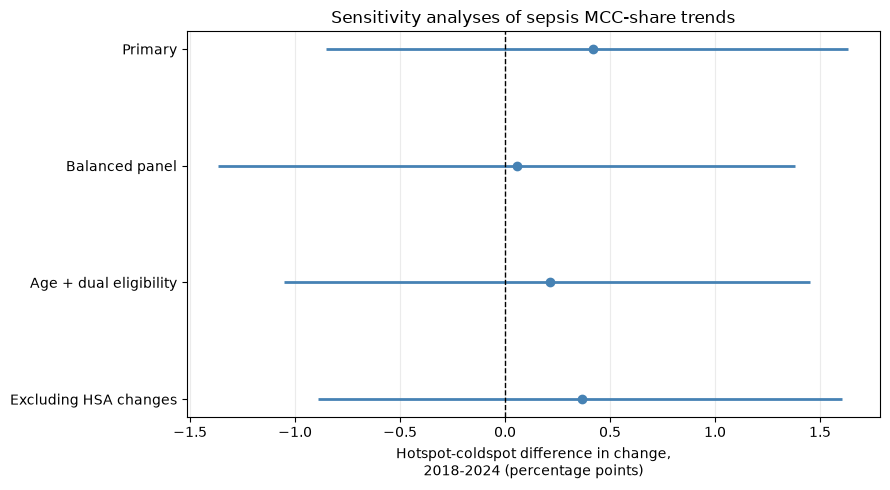

In [20]:
model_tables = {
    "Primary": results,
    "Balanced panel": balanced_results,
    "Age + dual eligibility": expanded_model,
    "Excluding HSA changes": hsa_sensitivity_results
}

rows = []

for name, table in model_tables.items():
    if table is None:
        continue

    endpoint = table.loc[
        table["term"] == "hotspot_x_2024"
    ]
    if len(endpoint) != 1:
        raise ValueError(f"Missing or duplicate 2024 estimate: {name}")

    row = endpoint.iloc[0]
    rows.append({
        "analysis": name,
        "estimate_pp": row["estimate_pp"],
        "lower": row["ci_lower_pp"],
        "upper": row["ci_upper_pp"]
    })

robustness = pd.DataFrame(rows)
display(robustness.round(3))

fig, ax = plt.subplots(figsize=(9, 5))

positions = np.arange(len(robustness))

ax.hlines(
    positions,
    robustness["lower"],
    robustness["upper"],
    color="steelblue",
    linewidth=2
)
ax.scatter(
    robustness["estimate_pp"],
    positions,
    color="steelblue",
    zorder=3
)
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_yticks(positions)
ax.set_yticklabels(robustness["analysis"])
ax.invert_yaxis()
ax.set(
    xlabel="Hotspot-coldspot difference in change,\n"
           "2018-2024 (percentage points)",
    title="Sensitivity analyses of sepsis MCC-share trends"
)

ax.grid(axis="x", alpha=0.25)
fig.tight_layout()

fig.savefig(OUTPUT_DIR / "robustness_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

#robustness.to_csv(OUTPUT_DIR / "robustness_comparison.csv", index=False)

> The estimated 2018–2024 differences remained small across the primary, balanced-panel, covariate-adjusted, and HSA-assignment analyses. All confidence intervals included zero. This consistency supports the conclusion that there was no clear evidence of differential increases.

In [21]:
# documenting observations, hospitals, & HSAs remaining at each selection stage

def sample_counts(frame, stage):
    return {
        "stage": stage,
        "hospital_years": len(
            frame[["hospital", "year"]].drop_duplicates()
        ),
        "hospitals": frame["hospital"].nunique(),
        "HSAs": frame["hsa"].nunique()
    }


flow = pd.DataFrame([
    sample_counts(data, "Sepsis records, 2018-2024, before geographic filtering"),
    sample_counts(eligible, "Hotspot/coldspot records with hospital and HSA identifiers"),
    sample_counts(complete_panel, "Both DRG counts reported"),
    sample_counts(primary, "Primary sample: at least two calculable years"),
    sample_counts(sensitivity, "Age/dual-eligibility complete-case sample"),
    sample_counts(balanced, "Balanced sample: all seven years")
])

display(flow)

# reasons for geographic exclusion (using mutually exclusive categories)

missing_ids = data["hospital"].isna() | data["hsa"].isna()
target_class = data["classification"].isin([HOT_LABEL, COLD_LABEL])

geographic_reason = np.select(
    [
        missing_ids,
        ~missing_ids & data["classification"].isna(),
        ~missing_ids & data["classification"].eq(0),
        ~missing_ids & target_class
    ],
    [
        "Missing hospital/HSA identifier",
        "Missing classification",
        "Neutral classification",
        "Retained hotspot/coldspot"
    ],
    default="Other classification"
)

print("Geographic filtering: DRG-row counts")
display(pd.Series(geographic_reason).value_counts())

#flow.to_csv(OUTPUT_DIR / "sample_flow.csv", index=False)

,stage,hospital_years,hospitals,HSAs
0,"Sepsis records, 2018-2024, before geographic filtering",4524,697,422
1,Hotspot/coldspot records with hospital and HSA identifiers,4524,697,422
2,Both DRG counts reported,3951,659,408
3,Primary sample: at least two calculable years,3917,625,386
4,Age/dual-eligibility complete-case sample,3916,625,386
5,Balanced sample: all seven years,3276,468,301


Geographic filtering: DRG-row counts


Retained hotspot/coldspot    8475
Name: count, dtype: int64

These results are in line with our prior analyses: There is no clear evidence that sepsis MCC shares increased differently in hotspots vs coldspots across this time period.
- conclusion is similar when using the same hospitals every years, adjusting for age & dual eligibility, or excluding the hospitals with changing HSA assignments

> This sample-flow table documents the compositional effect of geographic eligibility, complete DRG reporting, and minimum observation requirements on the analysis sample. The balanced-panel and covariate-adjusted samples are separate sensitivity-analysis branches. Hospital counts are distinguished from hospital-year counts due to the same hospital contributing observations across multiple years.

In [22]:
# testing the joint interaction of all six hotspot-x-year groups

import statsmodels.api as sm

joint_frame, X_joint, y_joint, joint_names = (
    prepare_fixed_effects(primary)
)

# hospital effects removed by demeaning
n_hospitals = joint_frame["hospital"].nunique()

joint_model = sm.OLS(y_joint, X_joint).fit()

joint_model.df_resid = (
    len(joint_frame)
    - n_hospitals
    - np.linalg.matrix_rank(X_joint)
)

clustered_model = joint_model.get_robustcov_results(
    cov_type="cluster",
    groups=joint_frame["hsa"].to_numpy(),
    use_correction=True,
    df_correction=True,
    use_t=True
)

interaction_positions = [
    i for i, name in enumerate(joint_names)
    if name.startswith("hotspot_x_")
]

R = np.zeros((len(interaction_positions), len(joint_names)))

for row, column in enumerate(interaction_positions):
    R[row, column] = 1

joint_test = clustered_model.wald_test(
    R,
    use_f=True,
    scalar=True
)

print(joint_test)
print("Joint-test p-value:", float(joint_test.pvalue))

<F test: F=1.5005276829515184, p=0.17666224370213593, df_denom=385, df_num=6>
Joint-test p-value: 0.17666224370213593


> The HSA-clustered joint test did not reject the hypothesis that all six hotspot-by-year interactions were zero (F(6,385)=1.50, p=0.177). This provides no clear overall evidence of different annual changes relative to 2018 and does not establish that the groups’ trends were identical.

#### Exploratory analysis using length of stay

in response to Subquestion 2: How did hospital-wide inpatient days per discharge change from 2018 to 2024 among hospitals in the sepsis analysis sample, and did these changes differ between AI-adoption hotspots and coldspots?

Loading inpatient-day data for 2018
Downloaded 3,249 rows
Loading inpatient-day data for 2019
Downloaded 3,198 rows
Loading inpatient-day data for 2020
Downloaded 3,156 rows
Loading inpatient-day data for 2021
Downloaded 3,134 rows
Loading inpatient-day data for 2022
Downloaded 3,120 rows
Loading inpatient-day data for 2023
Downloaded 3,093 rows
Loading inpatient-day data for 2024
Downloaded 3,044 rows
Hospital-years missing days per discharge: 0


,year,group,hospitals_with_days,mean_days,median_days
0,2018,Coldspot,207,4.51,4.37
1,2018,Hotspot,394,4.62,4.55
2,2019,Coldspot,202,4.53,4.42
3,2019,Hotspot,394,4.64,4.52
4,2020,Coldspot,191,4.84,4.77
5,2020,Hotspot,378,5.01,4.95
6,2021,Coldspot,184,5.15,5.14
7,2021,Hotspot,370,5.26,5.18
8,2022,Coldspot,171,5.03,5.0
9,2022,Hotspot,353,5.29,5.2


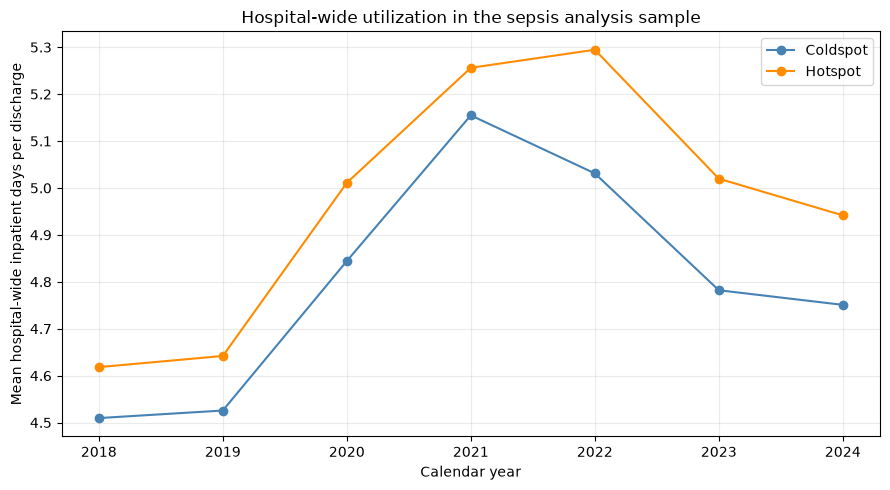

In [23]:
# using hospital-wide inpatient days summary
# (length of stay is not sepsis-specific)

los_frames = []

for year in YEARS:
    print(f"Loading inpatient-day data for {year}")

    frame = fetch_cms_data(PROVIDER_APIS[year])
    frame.columns = frame.columns.str.strip()

    needed = ["Rndrng_Prvdr_CCN", "Tot_Days", "Tot_Dschrgs"]

    missing = set(needed) - set(frame.columns)
    if missing:
        raise ValueError(f"{year}: missing fields {missing}")

    frame = frame[needed].copy()
    frame["year"] = year
    los_frames.append(frame)

provider_los = pd.concat(los_frames, ignore_index=True)

provider_los = provider_los.rename(columns={
    "Rndrng_Prvdr_CCN": "hospital",
    "Tot_Days": "hospital_days",
    "Tot_Dschrgs": "hospital_discharges"
})
for col in ["hospital_days", "hospital_discharges"]:
    provider_los[col] = pd.to_numeric(
        provider_los[col]
        .astype("string")
        .str.replace(",", "", regex=False),
        errors="coerce"
    )

if provider_los.duplicated(["hospital", "year"]).any():
    raise ValueError("Duplicate Provider hospital-year records")

provider_los["days_per_discharge"] = (
    provider_los["hospital_days"]
    / provider_los["hospital_discharges"].where(
        provider_los["hospital_discharges"] > 0
    )
)

los_panel = primary.merge(
    provider_los,
    on=["hospital", "year"],
    how="left",
    validate="one_to_one"
)
print(
    "Hospital-years missing days per discharge:",
    los_panel["days_per_discharge"].isna().sum()
)
los_summary = (
    los_panel.groupby(["year", "group"])
    .agg(
        hospitals_with_days=("days_per_discharge", "count"),
        mean_days=("days_per_discharge", "mean"),
        median_days=("days_per_discharge", "median")
    )
    .reset_index()
)

display(los_summary.round(2))

fig, ax = plt.subplots(figsize=(9, 5))

for group, subset in los_summary.groupby("group"):
    ax.plot(
        subset["year"],
        subset["mean_days"],
        marker="o",
        label=group,
        color=colors[group]
    )
ax.set(
    xlabel="Calendar year",
    ylabel="Mean hospital-wide inpatient days per discharge",
    title="Hospital-wide utilization in the sepsis analysis sample"
)
ax.set_xticks(YEARS)
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "hospital_wide_days_per_discharge.png", dpi=300, bbox_inches="tight")
plt.show()

#los_summary.to_csv(OUTPUT_DIR / "hospital_wide_days_summary.csv", index=False)

> Mean hospital-wide inpatient days per discharge increased from 4.51 to 4.75 in coldspots and from 4.62 to 4.94 in hotspots. These measures describe overall hospital utilization among hospitals in the sepsis sample, though they are not sepsis-specific lengths of stay.

In [24]:
# retaining hospital-years w/ valid inpatient-days-per-discharge values
# & hospitals w/ at least two usable years

los_analysis = los_panel.dropna(
    subset=["days_per_discharge"]
).copy()

usable_years = (
    los_analysis.groupby("hospital")["year"]
    .transform("nunique")
)
los_analysis = los_analysis.loc[usable_years >= 2].copy()

print("Hospital-year observations:", len(los_analysis))
print("Distinct hospitals:", los_analysis["hospital"].nunique())
print("Distinct HSAs:", los_analysis["hsa"].nunique())

display(
    los_analysis.groupby(["year", "group"]).agg(
        hospitals=("hospital", "nunique"),
        hsas=("hsa", "nunique"),
        mean_days=("days_per_discharge", "mean"),
        median_days=("days_per_discharge", "median")
    ).round(3)
)

Hospital-year observations: 3917
Distinct hospitals: 625
Distinct HSAs: 386


hospitals  hsas  mean_days  median_days
year group                                            
2018 Coldspot        207   149       4.51        4.368
     Hotspot         394   228      4.618        4.551
2019 Coldspot        202   145      4.526        4.422
     Hotspot         394   226      4.642        4.519
2020 Coldspot        191   136      4.844        4.768
     Hotspot         378   218      5.011        4.948
2021 Coldspot        184   134      5.155        5.136
     Hotspot         370   214      5.256        5.181
2022 Coldspot        171   126      5.031        4.999
     Hotspot         353   204      5.295        5.201
2023 Coldspot        171   124      4.782        4.698
     Hotspot         365   209       5.02        4.918
2024 Coldspot        175   128      4.751        4.606
     Hotspot         362   209      4.942        4.802

fitting utilization fixed-effects model with HSA-level bootstrapping

In [25]:
def bootstrap_outcome_model(frame, outcome, n_bootstraps=1000, seed=42):
    frame = frame.reset_index(drop=True).copy()

    # checking coverage
    coverage = (
        frame.groupby(["year", "group"])
        .size()
        .unstack(fill_value=0)
        .reindex(
            index=YEARS,
            columns=["Coldspot", "Hotspot"],
            fill_value=0
        )
    )
    if (coverage == 0).any().any():
        raise ValueError("At least one year lacks a geographic group")
    if frame.groupby("hospital")["hsa"].nunique().gt(1).any():
        raise ValueError("Hospital without a fixed HSA")
    hsa_labels = frame[["hsa", "group"]].drop_duplicates()
    if hsa_labels["hsa"].duplicated().any():
        raise ValueError("An HSA has conflicting group labels")

    X = pd.DataFrame(index=frame.index)
    hotspot = frame["classification"].eq(HOT_LABEL).astype(float)

    for year in YEARS:
        if year == REFERENCE_YEAR:
            continue
        indicator = frame["year"].eq(year).astype(float)
        X[f"year_{year}"] = indicator
        X[f"hotspot_x_{year}"] = indicator * hotspot

    y = frame[outcome].astype(float)

    # remove hospital means to account for hospital fixed effects
    X_within = (
        X - X.groupby(frame["hospital"]).transform("mean")
    ).to_numpy(dtype=float)

    y_within = (
        y - y.groupby(frame["hospital"]).transform("mean")
    ).to_numpy(dtype=float)

    def fit(x, y):
        if np.linalg.matrix_rank(x) < x.shape[1]:
            return None
        return np.linalg.lstsq(x, y, rcond=None)[0]

    point_estimate = fit(X_within, y_within)
    if point_estimate is None:
        raise ValueError("Model is not identifiable")

    clusters = frame.groupby("hsa", sort=False).indices

    group_hsas = {
        group: hsa_labels.loc[hsa_labels["group"].eq(group), "hsa"].to_numpy()
        for group in ["Coldspot", "Hotspot"]
    }
    if any(len(ids) < 2 for ids in group_hsas.values()):
        raise ValueError("Insufficient HSAs for bootstrapping")

    rng = np.random.default_rng(seed)
    estimates = []

    for b in range(n_bootstraps):
        sampled_hsas = []

        for group in ["Coldspot", "Hotspot"]:
            ids = group_hsas[group]
            sampled_hsas.extend(
                rng.choice(ids, size=len(ids), replace=True)
            )
        indices = np.concatenate([
            clusters[hsa] for hsa in sampled_hsas
        ])
        estimate = fit(
            X_within[indices],
            y_within[indices]
        )
        if estimate is not None:
            estimates.append(estimate)

        if (b + 1) % 200 == 0:
            print(f"Completed {b + 1}/{n_bootstraps}")

    if len(estimates) < 0.95 * n_bootstraps:
        raise ValueError("Too many non-identifiable bootstrap samples")

    lower, upper = np.quantile(
        np.vstack(estimates),
        [0.025, 0.975],
        axis=0
    )

    return pd.DataFrame({
        "term": X.columns,
        "estimate": point_estimate,
        "ci_lower": lower,
        "ci_upper": upper
    })

los_results = bootstrap_outcome_model(
    los_analysis,
    outcome="days_per_discharge",
    n_bootstraps=N_BOOTSTRAPS,
    seed=RANDOM_SEED
)

los_interactions = los_results.loc[
    los_results["term"].str.startswith("hotspot_x_")
].copy()

los_interactions["year"] = (
    los_interactions["term"]
    .str.extract(r"(\d{4})")[0]
    .astype(int)
)

display(los_interactions.round(3))

Completed 200/1000
Completed 400/1000
Completed 600/1000
Completed 800/1000
Completed 1000/1000


,term,estimate,ci_lower,ci_upper,year
1,hotspot_x_2019,0.015,-0.033,0.063,2019
3,hotspot_x_2020,0.062,-0.013,0.140,2020
5,hotspot_x_2021,0.019,-0.073,0.114,2021
7,hotspot_x_2022,0.195,0.066,0.327,2022
9,hotspot_x_2023,0.190,0.066,0.313,2023
11,hotspot_x_2024,0.155,0.032,0.281,2024


plotting adjusted utilization
- hotspot-coldspot differences in changes in days per discharge (relative to 2018)

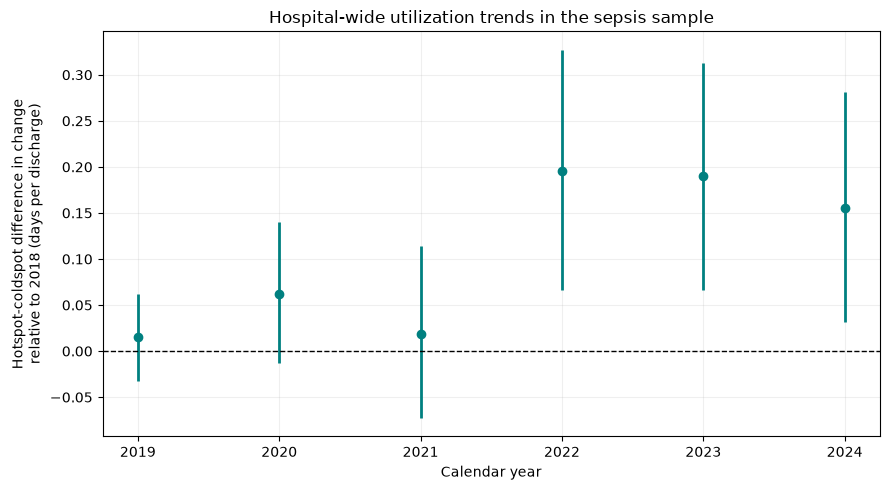

In [26]:
plot_data = los_interactions.sort_values("year")

fig, ax = plt.subplots(figsize=(9, 5))

ax.vlines(
    plot_data["year"],
    plot_data["ci_lower"],
    plot_data["ci_upper"],
    color="teal",
    linewidth=2
)

ax.scatter(
    plot_data["year"],
    plot_data["estimate"],
    color="teal",
    zorder=3
)
ax.axhline(0, color="black", linestyle="--", linewidth=1)

ax.set(
    xlabel="Calendar year",
    ylabel="Hotspot-coldspot difference in change\n"
           "relative to 2018 (days per discharge)",
    title="Hospital-wide utilization trends in the sepsis sample"
)
ax.set_xticks(
    [year for year in YEARS if year != REFERENCE_YEAR]
)
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "adjusted_hospital_days_trends.png", dpi=300, bbox_inches="tight")
plt.show()

#los_results.to_csv(OUTPUT_DIR / "hospital_days_fixed_effects.csv", index=False)

balanced utilization analysis: for hospitals observed in all years
- checking sensitivity to sample composition

In [27]:
los_year_counts = (los_analysis.groupby("hospital")["year"].nunique())

los_balanced_ids = los_year_counts[los_year_counts == len(YEARS)].index

los_balanced = los_analysis.loc[los_analysis["hospital"].isin(los_balanced_ids)].copy()

los_balanced_counts = (
    los_balanced.groupby("group")["hsa"].nunique()
    .reindex(["Coldspot", "Hotspot"], fill_value=0)
)

los_balanced_results = None

if los_balanced_counts.min() >= 2:
    los_balanced_results = bootstrap_outcome_model(
        los_balanced,
        outcome="days_per_discharge",
        n_bootstraps=N_BOOTSTRAPS,
        seed=RANDOM_SEED + 1
    )

    display(
        los_balanced_results.loc[
            los_balanced_results["term"] == "hotspot_x_2024"
        ].round(3)
    )
else:
    print("Insufficient HSAs for balanced-panel analysis")

Completed 200/1000
Completed 400/1000
Completed 600/1000
Completed 800/1000
Completed 1000/1000


,term,estimate,ci_lower,ci_upper
11,hotspot_x_2024,0.117,-0.027,0.243


utilization results summary

In [28]:
los_annual = (
    los_analysis.groupby(["year", "group"])["days_per_discharge"]
    .mean()
    .unstack("group")
)

for group in ["Coldspot", "Hotspot"]:
    first = los_annual.loc[2018, group]
    last = los_annual.loc[2024, group]

    print(
        f"{group}: mean hospital-wide days per discharge "
        f"changed from {first:.2f} in 2018 to {last:.2f} in 2024."
    )

endpoint = los_interactions.loc[
    los_interactions["year"] == 2024
].iloc[0]

print(
    "\nAdjusted hotspot-coldspot difference in change: "
    f"{endpoint['estimate']:.3f} days per discharge "
    f"(95% bootstrap CI "
    f"{endpoint['ci_lower']:.3f} to "
    f"{endpoint['ci_upper']:.3f})."
)

Coldspot: mean hospital-wide days per discharge changed from 4.51 in 2018 to 4.75 in 2024.
Hotspot: mean hospital-wide days per discharge changed from 4.62 in 2018 to 4.94 in 2024.

Adjusted hotspot-coldspot difference in change: 0.155 days per discharge (95% bootstrap CI 0.032 to 0.281).


> The adjusted 2018–2024 increase in hospital-wide days per discharge was 0.155 days greater in hotspots (95% bootstrap CI: 0.032 to 0.281), equal to approximately 3.7 hours. The interval excludes zero, suggesting evidence of a definitive difference while noting that this finding cannot establish changes in sepsis-specific care, inappropriate coding, or an effect of AI adoption.

#### Overall interpretation

Sepsis MCC shares increased in both groups with no clear differential change across the primary and secondary analyses. Hospital-wide days per discharge showed a greater adjusted increase in hotspots.

Because the outcomes cover different patient groupings and hotspot labels describe regional predictive-AI implementation, these findings characterize associations rather than demonstrate whether AI changed coding or treatment.